<a href="https://colab.research.google.com/github/zeeshan9595/lending-club-credit-decisions/blob/main/lending_club_credit_decisions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Lending Club: leakage-aware credit approval, profit thresholds and thin-file fairness
# Author: Zeeshan Azeem Khalid
# Data: Lending Club accepted loans 2007-2018Q4, Kaggle (wordsforthewise/lending-club), CC0 public domain
!pip -q install kagglehub lightgbm shap
import kagglehub, glob, os
path = kagglehub.dataset_download("wordsforthewise/lending-club")
files = sorted(glob.glob(path + "/**/*.csv*", recursive=True))
print(files)

100%|██████████| 1.26G/1.26G [00:20<00:00, 67.0MB/s]

Extracting files...


['/root/.cache/kagglehub/datasets/wordsforthewise/lending-club/versions/3/accepted_2007_to_2018Q4.csv.gz', '/root/.cache/kagglehub/datasets/wordsforthewise/lending-club/versions/3/accepted_2007_to_2018q4.csv', '/root/.cache/kagglehub/datasets/wordsforthewise/lending-club/versions/3/accepted_2007_to_2018q4.csv/accepted_2007_to_2018Q4.csv', '/root/.cache/kagglehub/datasets/wordsforthewise/lending-club/versions/3/rejected_2007_to_2018Q4.csv.gz', '/root/.cache/kagglehub/datasets/wordsforthewise/lending-club/versions/3/rejected_2007_to_2018q4.csv', '/root/.cache/kagglehub/datasets/wordsforthewise/lending-club/versions/3/rejected_2007_to_2018q4.csv/rejected_2007_to_2018Q4.csv']


In [2]:
# ---------- 1. Load, define the target, and build a time-ordered sample ----------
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json, warnings
warnings.filterwarnings("ignore")
os.makedirs("figures", exist_ok=True)

acc = [f for f in files if "accepted" in os.path.basename(f)][0]
APP = ["loan_amnt","term","emp_length","home_ownership","annual_inc","verification_status",
       "purpose","dti","delinq_2yrs","earliest_cr_line","fico_range_low","fico_range_high",
       "inq_last_6mths","open_acc","pub_rec","revol_bal","revol_util","total_acc","mort_acc",
       "pub_rec_bankruptcies","application_type"]
PRICING = ["int_rate","grade"]                      # set by Lending Club's own risk model
LEAKY = ["total_pymnt","total_rec_prncp","recoveries","collection_recovery_fee",
         "last_pymnt_amnt","last_fico_range_high","debt_settlement_flag"]   # only known after the loan
df = pd.read_csv(acc, usecols=APP + PRICING + LEAKY + ["issue_d","loan_status","funded_amnt"], low_memory=False)
print("Raw accepted loans:", f"{len(df):,}")

df["issue_d"] = pd.to_datetime(df["issue_d"], format="%b-%Y")
df = df[(df["term"].str.strip() == "36 months") & (df.issue_d >= "2012-01-01") & (df.issue_d < "2016-01-01")]
n_window = len(df)
bad  = ["Charged Off", "Default", "Does not meet the credit policy. Status:Charged Off"]
good = ["Fully Paid", "Does not meet the credit policy. Status:Fully Paid"]
df = df[df.loan_status.isin(bad + good)].copy()
print(f"36-month loans issued 2012-2015: {n_window:,}; resolved (paid or charged off): {len(df):,} ({len(df)/n_window:.1%})")

df["y"] = df.loan_status.isin(bad).astype(int)
ecl = pd.to_datetime(df["earliest_cr_line"], format="%b-%Y", errors="coerce")
df["credit_hist_yrs"] = (df.issue_d - ecl).dt.days / 365.25
df["thin_file"] = np.where(df.credit_hist_yrs < 5, "Under 5 yrs credit history", "5+ yrs credit history")
df["emp_length"] = pd.to_numeric(df.emp_length.str.replace("< 1", "0").str.extract(r"(\d+)")[0], errors="coerce")
df["pnl"] = df.total_pymnt - df.funded_amnt        # realised cash outcome: used for evaluation only, never as a feature
df["year"] = df.issue_d.dt.year
CAT = ["home_ownership","verification_status","purpose","application_type","grade","debt_settlement_flag"]
for c in CAT:
    df[c] = df[c].astype("category")

summary = df.groupby("year").agg(loans=("y","size"), default_rate=("y","mean"), avg_pnl=("pnl","mean"))
print(summary.round(3))
print(df.groupby("thin_file").agg(loans=("y","size"), default_rate=("y","mean")).round(3))

# Time-ordered split: train 2012-13, validate 2014 (early stopping + threshold choice), test 2015 (untouched)
tr, va, te = df[df.year <= 2013], df[df.year == 2014], df[df.year == 2015]
print("train / valid / test:", len(tr), len(va), len(te))

Raw accepted loans: 2,260,701
36-month loans issued 2012-2015: 589,635; resolved (paid or charged off): 589,488 (100.0%)
       loans  default_rate   avg_pnl
year                                
2012   43470         0.136  1189.657
2013  100422         0.123  1399.961
2014  162570         0.137  1132.168
2015  283026         0.149   838.909
                             loans  default_rate
thin_file                                       
5+ yrs credit history       573528         0.139
Under 5 yrs credit history   15960         0.188
train / valid / test: 143892 162570 283026


LEAKAGE AUDIT (test = 2015 loans)
                                                roc_auc  pr_auc   brier
A. Includes post-loan fields (leaky)            0.9995  0.9984  0.0048
B. Application data + Lending Club grade/rate   0.6860  0.2638  0.1214
C. Application data only (final model)          0.6653  0.2453  0.1216


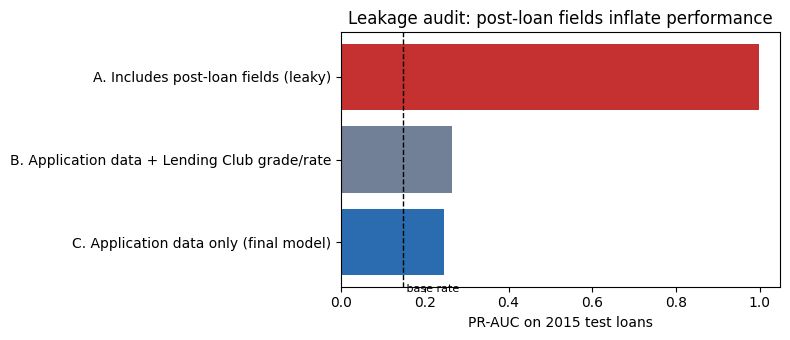


MODEL COMPARISON (test = 2015)
                      roc_auc  pr_auc   brier
Logistic regression   0.6515  0.2322  0.1226
LightGBM              0.6653  0.2453  0.1216 
base default rate: 0.1489

PROFIT: threshold chosen on 2014 = PD < 0.56
2015 realised P&L, approve all LC-approved loans: 237.4m USD
2015 realised P&L at chosen threshold: 237.4m USD, approval rate 100.0%
Best threshold in hindsight on 2015: 238.2m USD


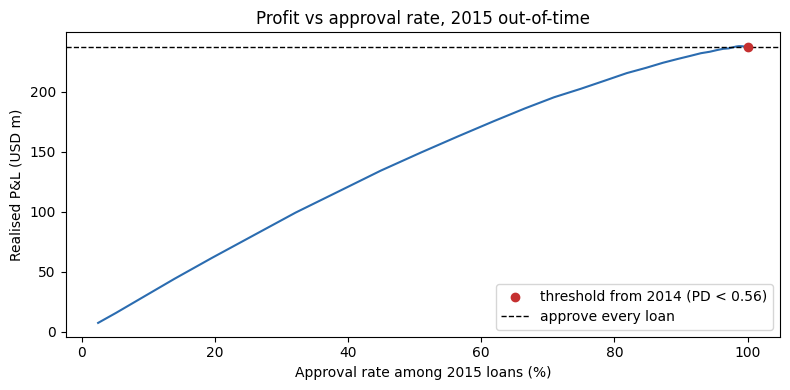


THIN-FILE FAIRNESS (2015, LightGBM at chosen threshold)
 group                    5+ yrs credit history  Under 5 yrs credit history
loans                               274494.000                    8532.000
default_rate                             0.147                       0.193
mean_predicted_pd                        0.128                       0.174
approval_rate                            1.000                       1.000
good_borrowers_declined                  0.000                       0.000
defaulters_approved                      1.000                       1.000
roc_auc                                  0.666                       0.629
pnl_per_approved_loan                  848.099                     543.244


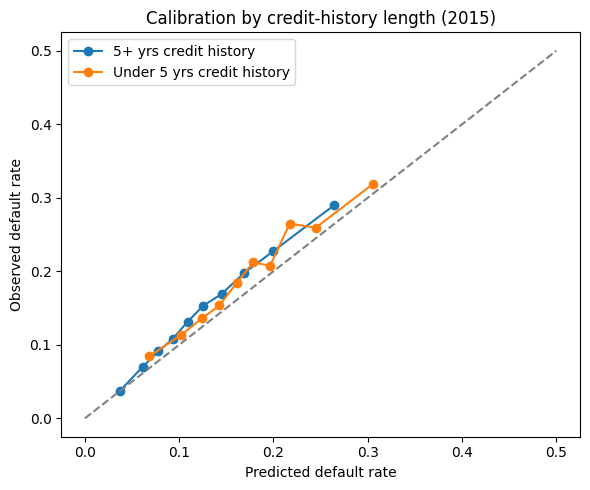

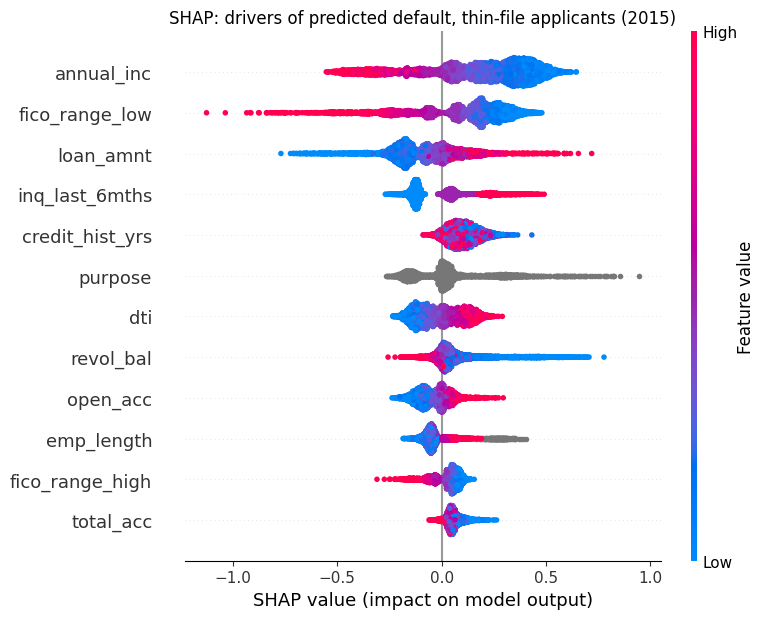


Top SHAP drivers (thin-file):
 annual_inc         0.2781
fico_range_low     0.2202
loan_amnt          0.1448
inq_last_6mths     0.1234
credit_hist_yrs    0.1033
purpose            0.0982
dti                0.0936
revol_bal          0.0924
dtype: float64

RESULTS_JSON {"window_loans": 589635, "resolved_loans": 589488, "split_sizes": [143892, 162570, 283026], "test_default_rate": 0.14886264866125373, "leakage_audit": {"A. Includes post-loan fields (leaky)": {"roc_auc": 0.9995, "pr_auc": 0.9984, "brier": 0.0048}, "B. Application data + Lending Club grade/rate": {"roc_auc": 0.686, "pr_auc": 0.2638, "brier": 0.1214}, "C. Application data only (final model)": {"roc_auc": 0.6653, "pr_auc": 0.2453, "brier": 0.1216}}, "models": {"Logistic regression": {"roc_auc": 0.6515, "pr_auc": 0.2322, "brier": 0.1226}, "LightGBM": {"roc_auc": 0.6653, "pr_auc": 0.2453, "brier": 0.1216}}, "threshold": 0.56, "pnl_approve_all_m": 237.43, "pnl_threshold_m": 237.43, "approval_rate": 1.0, "pnl_hindsight_best_m": 

In [3]:
# ---------- 2. Leakage audit, models, profit thresholds, thin-file fairness, SHAP ----------
import lightgbm as lgb, shap
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss

NUM = ["loan_amnt","emp_length","annual_inc","dti","delinq_2yrs","fico_range_low","fico_range_high",
       "inq_last_6mths","open_acc","pub_rec","revol_bal","revol_util","total_acc","mort_acc",
       "pub_rec_bankruptcies","credit_hist_yrs"]
APPCAT = ["home_ownership","verification_status","purpose","application_type"]
FINAL = NUM + APPCAT

def fit_lgb(cols):
    m = lgb.LGBMClassifier(n_estimators=3000, learning_rate=0.03, num_leaves=31, min_child_samples=200,
                           subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=42, verbose=-1)
    m.fit(tr[cols], tr.y, eval_set=[(va[cols], va.y)], callbacks=[lgb.early_stopping(100, verbose=False)])
    return m

def scores(y, p):
    return dict(roc_auc=roc_auc_score(y, p), pr_auc=average_precision_score(y, p), brier=brier_score_loss(y, p))

# 2a. Leakage audit: the same model with and without fields that only exist after the loan
variants = {
    "A. Includes post-loan fields (leaky)": FINAL + PRICING + [c for c in LEAKY if c != "total_pymnt"],
    "B. Application data + Lending Club grade/rate": FINAL + PRICING,
    "C. Application data only (final model)": FINAL,
}
audit = {}
for name, cols in variants.items():
    m = fit_lgb(cols)
    audit[name] = scores(te.y, m.predict_proba(te[cols])[:, 1])
    if name.startswith("C"):
        gbm = m
audit = pd.DataFrame(audit).T
print("LEAKAGE AUDIT (test = 2015 loans)\n", audit.round(4))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(audit.index[::-1], audit.pr_auc[::-1], color=["#2b6cb0", "#718096", "#c53030"])
ax.axvline(te.y.mean(), ls="--", c="k", lw=1); ax.text(te.y.mean(), -0.6, " base rate", fontsize=8)
ax.set_xlabel("PR-AUC on 2015 test loans"); ax.set_title("Leakage audit: post-loan fields inflate performance")
plt.tight_layout(); plt.savefig("figures/1_leakage_audit.png", dpi=150); plt.show()

# 2b. Interpretable baseline vs gradient boosting on application data only
pre = make_column_transformer(
    (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUM),
    (make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore")), APPCAT))
logit = make_pipeline(pre, LogisticRegression(max_iter=2000))
Xlr = lambda d: d[NUM].join(d[APPCAT].astype(str))
logit.fit(Xlr(tr), tr.y)
p = {"Logistic regression": {s: logit.predict_proba(Xlr(d))[:, 1] for s, d in [("va", va), ("te", te)]},
     "LightGBM":            {s: gbm.predict_proba(d[FINAL])[:, 1]  for s, d in [("va", va), ("te", te)]}}
models = pd.DataFrame({k: scores(te.y, v["te"]) for k, v in p.items()}).T
print("\nMODEL COMPARISON (test = 2015)\n", models.round(4), "\nbase default rate:", round(te.y.mean(), 4))

# 2c. Profit-based approval threshold: chosen on 2014, applied to 2015
grid = np.round(np.arange(0.03, 0.61, 0.01), 2)
def curve(d, pr):
    return pd.DataFrame([(t, d.pnl[pr < t].sum(), (pr < t).mean()) for t in grid], columns=["t", "pnl", "approval"])
cv_va, cv_te = curve(va, p["LightGBM"]["va"]), curve(te, p["LightGBM"]["te"])
t_star = float(cv_va.loc[cv_va.pnl.idxmax(), "t"])
row = cv_te[cv_te.t == t_star].iloc[0]
approve_all = te.pnl.sum()
best_possible = float(cv_te.pnl.max())
print(f"\nPROFIT: threshold chosen on 2014 = PD < {t_star:.2f}")
print(f"2015 realised P&L, approve all LC-approved loans: {approve_all/1e6:,.1f}m USD")
print(f"2015 realised P&L at chosen threshold: {row.pnl/1e6:,.1f}m USD, approval rate {row.approval:.1%}")
print(f"Best threshold in hindsight on 2015: {best_possible/1e6:,.1f}m USD")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(cv_te.approval * 100, cv_te.pnl / 1e6, c="#2b6cb0")
ax.scatter([row.approval * 100], [row.pnl / 1e6], c="#c53030", zorder=3, label=f"threshold from 2014 (PD < {t_star:.2f})")
ax.axhline(approve_all / 1e6, ls="--", c="k", lw=1, label="approve every loan")
ax.set_xlabel("Approval rate among 2015 loans (%)"); ax.set_ylabel("Realised P&L (USD m)")
ax.set_title("Profit vs approval rate, 2015 out-of-time"); ax.legend(); plt.tight_layout()
plt.savefig("figures/2_profit_curve.png", dpi=150); plt.show()

# 2d. Thin-file fairness at the chosen threshold
te = te.assign(pd_hat=p["LightGBM"]["te"])
te["approved"] = te.pd_hat < t_star
rows = []
for g, d in te.groupby("thin_file"):
    rows.append(dict(group=g, loans=len(d), default_rate=d.y.mean(), mean_predicted_pd=d.pd_hat.mean(),
                     approval_rate=d.approved.mean(),
                     good_borrowers_declined=1 - d[d.y == 0].approved.mean(),
                     defaulters_approved=d[d.y == 1].approved.mean(),
                     roc_auc=roc_auc_score(d.y, d.pd_hat), pnl_per_approved_loan=d.pnl[d.approved].mean()))
fair = pd.DataFrame(rows).set_index("group")
print("\nTHIN-FILE FAIRNESS (2015, LightGBM at chosen threshold)\n", fair.round(3).T)

fig, ax = plt.subplots(figsize=(6, 5))
for g, d in te.groupby("thin_file"):
    b = d.groupby(pd.qcut(d.pd_hat, 10, duplicates="drop")).agg(pred=("pd_hat", "mean"), obs=("y", "mean"))
    ax.plot(b.pred, b.obs, marker="o", label=g)
ax.plot([0, 0.5], [0, 0.5], ls="--", c="grey"); ax.set_xlabel("Predicted default rate"); ax.set_ylabel("Observed default rate")
ax.set_title("Calibration by credit-history length (2015)"); ax.legend(); plt.tight_layout()
plt.savefig("figures/3_calibration_by_group.png", dpi=150); plt.show()

# 2e. SHAP: what drives predictions for thin-file applicants
thin = te[te.thin_file.str.startswith("Under")]
smp = thin.sample(min(5000, len(thin)), random_state=0)[FINAL]
sv = shap.TreeExplainer(gbm).shap_values(smp)
sv = sv[1] if isinstance(sv, list) else sv
shap.summary_plot(sv, smp, max_display=12, show=False)
plt.title("SHAP: drivers of predicted default, thin-file applicants (2015)"); plt.tight_layout()
plt.savefig("figures/4_shap_thin_file.png", dpi=150, bbox_inches="tight"); plt.show()
top = pd.Series(np.abs(sv).mean(0), index=FINAL).sort_values(ascending=False).head(8)
print("\nTop SHAP drivers (thin-file):\n", top.round(4))

results = dict(window_loans=int(n_window), resolved_loans=int(len(df)), split_sizes=[len(tr), len(va), len(te)],
               test_default_rate=float(te.y.mean()), leakage_audit=audit.round(4).to_dict("index"),
               models=models.round(4).to_dict("index"), threshold=t_star,
               pnl_approve_all_m=round(approve_all/1e6, 2), pnl_threshold_m=round(float(row.pnl)/1e6, 2),
               approval_rate=round(float(row.approval), 4), pnl_hindsight_best_m=round(best_possible/1e6, 2),
               fairness=fair.round(4).to_dict("index"), top_shap_thin=top.round(4).to_dict())
json.dump(results, open("results.json", "w"), indent=2)
print("\nRESULTS_JSON", json.dumps(results))

FUNDING-COST SENSITIVITY (2015 test, USD m)
  funding_cost  threshold_from_2014  approval_rate_2015  pnl_approve_all_m  pnl_policy_m  uplift_m
         0.00                 0.56               1.000            237.433       237.433     0.000
         0.03                 0.31               0.987             74.340        77.186     2.846
         0.05                 0.20               0.847            -34.389       -13.500    20.890
         0.07                 0.03               0.025           -143.118        -3.669   139.450


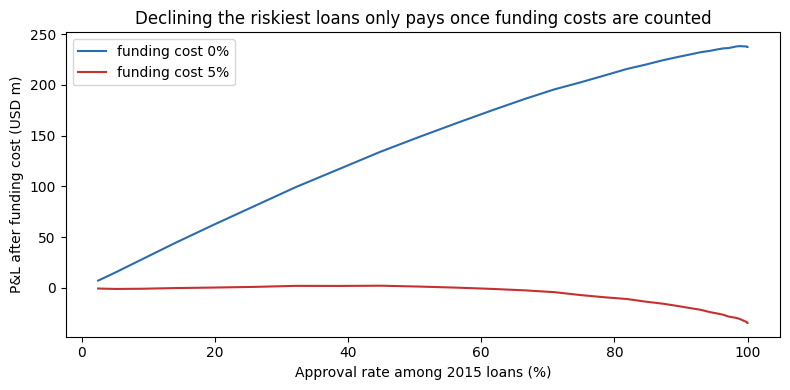


FIXED-CUT FAIRNESS (2015)
               policy                      group  loans  default_rate  mean_predicted_pd  declined_share  good_borrowers_declined  defaulters_caught  roc_auc
decline riskiest 10%      5+ yrs credit history 274494         0.147              0.128           0.096                    0.080              0.190    0.666
decline riskiest 10% Under 5 yrs credit history   8532         0.193              0.174           0.228                    0.202              0.333    0.629
decline riskiest 20%      5+ yrs credit history 274494         0.147              0.128           0.193                    0.168              0.341    0.666
decline riskiest 20% Under 5 yrs credit history   8532         0.193              0.174           0.419                    0.383              0.571    0.629

CALIBRATION DRIFT, 2015 (model trained on 2012-13)
                             predicted  observed
thin_file                                      
5+ yrs credit history          0.1282 

In [5]:
# ---------- 3. Stress-testing the economics and a fixed-cut fairness check ----------
# Raw realised P&L ignores the cost of money. A repaid 36-month amortising loan is outstanding ~1.5 years on average,
# so we subtract an assumed annual funding cost on the funded amount. These rates are assumptions, not Lending Club data.
pg_va, pg_te = p["LightGBM"]["va"], p["LightGBM"]["te"]
econ = []
for r in [0.00, 0.03, 0.05, 0.07]:
    adj_va = va.pnl - va.funded_amnt * r * 1.5
    adj_te = te.pnl - te.funded_amnt * r * 1.5
    pv = [adj_va[pg_va < t].sum() for t in grid]
    t_r = float(grid[int(np.argmax(pv))])
    keep = pg_te < t_r
    econ.append(dict(funding_cost=r, threshold_from_2014=t_r, approval_rate_2015=keep.mean(),
                     pnl_approve_all_m=adj_te.sum()/1e6, pnl_policy_m=adj_te[keep].sum()/1e6,
                     uplift_m=(adj_te[keep].sum() - adj_te.sum())/1e6))
econ = pd.DataFrame(econ)
print("FUNDING-COST SENSITIVITY (2015 test, USD m)\n", econ.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4))
for r, col in zip([0.00, 0.05], ["#2b6cb0", "#c53030"]):
    adj = te.pnl - te.funded_amnt * r * 1.5
    ax.plot([(pg_te < t).mean()*100 for t in grid], [adj[pg_te < t].sum()/1e6 for t in grid], c=col, label=f"funding cost {r:.0%}")
ax.set_xlabel("Approval rate among 2015 loans (%)"); ax.set_ylabel("P&L after funding cost (USD m)")
ax.set_title("Declining the riskiest loans only pays once funding costs are counted"); ax.legend(); plt.tight_layout()
plt.savefig("figures/2_profit_curve.png", dpi=150); plt.show()

# Fixed-cut policy: decline the riskiest X% of 2015 applicants by predicted PD, compare groups
cut_rows = []
for cut in [0.10, 0.20]:
    thr = np.quantile(pg_te, 1 - cut)
    for g, d in te.groupby("thin_file"):
        dec = d.pd_hat >= thr
        cut_rows.append(dict(policy=f"decline riskiest {cut:.0%}", group=g, loans=len(d), default_rate=d.y.mean(),
                             mean_predicted_pd=d.pd_hat.mean(), declined_share=dec.mean(),
                             good_borrowers_declined=dec[d.y == 0].mean(), defaulters_caught=dec[d.y == 1].mean(),
                             roc_auc=roc_auc_score(d.y, d.pd_hat)))
cuts = pd.DataFrame(cut_rows)
print("\nFIXED-CUT FAIRNESS (2015)\n", cuts.round(3).to_string(index=False))

drift = te.groupby("thin_file").agg(predicted=("pd_hat", "mean"), observed=("y", "mean"))
print("\nCALIBRATION DRIFT, 2015 (model trained on 2012-13)\n", drift.round(4))

results.update(funding_sensitivity=econ.round(4).to_dict("records"), fixed_cut_fairness=cuts.round(4).to_dict("records"),
               calibration_2015=drift.round(4).to_dict("index"))
json.dump(results, open("results.json", "w"), indent=2)
print(json.dumps({k: results[k] for k in ["funding_sensitivity", "fixed_cut_fairness", "calibration_2015"]}))

In [6]:
print(econ.round(3).to_string(index=False)); print(cuts.round(3).to_string(index=False)); print(drift.round(4))

 funding_cost  threshold_from_2014  approval_rate_2015  pnl_approve_all_m  pnl_policy_m  uplift_m
         0.00                 0.56               1.000            237.433       237.433     0.000
         0.03                 0.31               0.987             74.340        77.186     2.846
         0.05                 0.20               0.847            -34.389       -13.500    20.890
         0.07                 0.03               0.025           -143.118        -3.669   139.450
              policy                      group  loans  default_rate  mean_predicted_pd  declined_share  good_borrowers_declined  defaulters_caught  roc_auc
decline riskiest 10%      5+ yrs credit history 274494         0.147              0.128           0.096                    0.080              0.190    0.666
decline riskiest 10% Under 5 yrs credit history   8532         0.193              0.174           0.228                    0.202              0.333    0.629
decline riskiest 20%      5+ yrs credit